# 06 - Reliable Rating: Player Signal and Shrinkage Constants

Estimates how much of a match rating is stable player quality and how much is match-to-match noise, then fits the constants of the reliable rating (`src/services/analytics/reliable_rating_service.py`) from that: the prior mean, the between-player variance (`PRIOR_VARIANCE`), the within-player variance (`OBSERVATION_VARIANCE`) and, only if the data can identify it, the season drift (`SEASON_DRIFT_VARIANCE`). The constants depend on the live rating config, so this notebook is re-run after every promoted refit.

**Design (fixed before running).**
- Model: rating = grand mean + player effect + match noise, a one-way random-effects model fitted by REML (`workshop/lib/reliable_rating.py`). `k` = within / between variance is the weight of the prior in appearances.
- Data: every rated appearance from the `pool` careers, ratings recomputed with the live config, rows pooled (careers weighted by their rows, not balanced).
- Uncertainty: percentile bootstrap over players (1000 resamples); the player is the independent unit.
- Generalisation: leave-one-career-out. Constants are fitted on the other careers and scored by one-step-ahead (walk-forward) prediction on the held-out career, against the raw running mean and the constant prior.
- Prior mean: the fitted grand mean replaces the hard-coded 6.0 only if, held out and at the same `k`, it predicts better than 6.0 and the paired bootstrap interval (over players) of the squared-error gain excludes 0.
- Shrinkage strength: the REML `k` is the recommended value; the walk-forward sweep over `k` is a cross-check, not a second estimator.
- Drift: `q` stays 0 unless at least two careers have 10 or more players spanning two or more seasons, the best `q` beats 0 in held-out log density in each of those careers, and a paired bootstrap interval over players excludes 0.
- Out of scope: minutes weighting (match ratings already handle it) and position-specific priors (checked descriptively only).

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_root = Path("..").resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.services.analytics.reliable_rating_service import ReliableRatingService
from workshop.lib import inference
from workshop.lib import reliable_rating as rr
from workshop.lib.report import header, say, span

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
info = header()

**Validated config: `005d563f`** | run 2026-10-25

- Config fitted on: arsenal_2 1-38, ipswich_3 1-22, valencia_cf_1 1-157
- Data analysed (matches per career): arsenal_2 (38), ipswich_3 (22), valencia_cf_1 (157)

## Data

In [3]:
SEED = inference.DEFAULT_SEED
N_BOOT = 1000
MIN_MULTI_SEASON_PLAYERS = 10

frame = rr.appearance_frame("pool")
summaries = rr.player_summaries(frame)
summaries["career"] = summaries.index.str.split(":").str[0]
seasons_per_player = frame.groupby("player_key")["season"].nunique()

inventory = frame.groupby("career").agg(
    rows=("rating", "size"),
    players=("player_key", "nunique"),
    first_season=("season", "min"),
    last_season=("season", "max"),
)
inventory["median_appearances"] = summaries.groupby("career")["n"].median()
inventory["players_10plus"] = summaries[summaries["n"] >= 10].groupby("career").size()
inventory["players_multi_season"] = (
    seasons_per_player[seasons_per_player >= 2]
    .groupby(lambda key: key.split(":")[0])
    .size()
)
inventory = inventory.fillna(0).astype({"players_10plus": int, "players_multi_season": int})
display(inventory)

identifiable = inventory.index[inventory["players_multi_season"] >= MIN_MULTI_SEASON_PLAYERS].tolist()
say(
    f"**{len(frame):,} rated appearances** by {frame['player_key'].nunique()} players across "
    f"{len(inventory)} careers. Careers with at least {MIN_MULTI_SEASON_PLAYERS} players spanning two or "
    f"more seasons: {', '.join(identifiable) if identifiable else 'none'}. Season drift can only be "
    f"identified from careers like that, so it has {len(identifiable)} to learn from."
)

,rows,players,first_season,last_season,median_appearances,players_10plus,players_multi_season
career,,,,,,,
arsenal_2,570,27,2026,2026,23.000,22,0
ipswich_3,313,25,2026,2026,13.000,15,0
valencia_cf_1,2376,44,2029,2031,43.000,33,23


**3,259 rated appearances** by 96 players across 3 careers. Careers with at least 10 players spanning two or more seasons: valencia_cf_1. Season drift can only be identified from careers like that, so it has 1 to learn from.

## Variance components

,estimate,ci_low,ci_high
mu,6.442,6.368,6.515
within_var,0.826,0.716,0.948
between_var,0.088,0.048,0.136
k,9.361,5.970,17.529
icc,0.097,0.054,0.143


Row-pooled REML fit over 96 players: grand mean **6.442** (6.368 to 6.515), within-player variance **0.826** (0.716 to 0.948), between-player variance **0.088** (0.048 to 0.136). Only **9.7%** of a single match rating's variance is stable player quality (ICC 0.054 to 0.143). The prior therefore carries the weight of **k = 9.4** appearances (6.0 to 17.5). A player's mean is 52% reliable after 10 appearances, 76% after 30 and 87% after 60. The hard-coded prior mean of 6.0 lies outside the interval for the grand mean. 0% of bootstrap resamples showed no player effect at all.

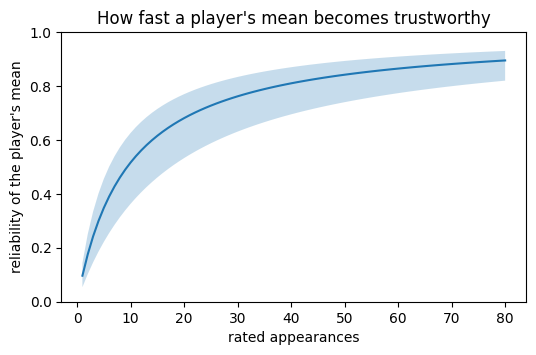

In [4]:
fit = rr.fit_variance_components(summaries)
draws = rr.bootstrap_variance_components(summaries, n_resamples=N_BOOT, seed=SEED)
table = rr.summarise_bootstrap(fit, draws)
display(table)


def bounds(name: str, digits: int = 3) -> str:
    return span(table.loc[name, "ci_low"], table.loc[name, "ci_high"], digits)


zero_share = float((draws["between_var"] == 0).mean())
six_inside = table.loc["mu", "ci_low"] <= 6.0 <= table.loc["mu", "ci_high"]
say(
    f"Row-pooled REML fit over {fit.n_players} players: grand mean **{fit.mu:.3f}** ({bounds('mu')}), "
    f"within-player variance **{fit.within_var:.3f}** ({bounds('within_var')}), between-player variance "
    f"**{fit.between_var:.3f}** ({bounds('between_var')}). Only **{fit.icc:.1%}** of a single match "
    f"rating's variance is stable player quality (ICC {bounds('icc')}). The prior therefore carries the "
    f"weight of **k = {fit.k:.1f}** appearances ({bounds('k', 1)}). A player's mean is "
    f"{fit.reliability(10):.0%} reliable after 10 appearances, {fit.reliability(30):.0%} after 30 and "
    f"{fit.reliability(60):.0%} after 60. The hard-coded prior mean of 6.0 lies "
    f"{'inside' if six_inside else 'outside'} the interval for the grand mean. "
    f"{zero_share:.0%} of bootstrap resamples showed no player effect at all."
)

ns = np.arange(1, 81)
between = draws["between_var"].to_numpy()[:, None]
within = draws["within_var"].to_numpy()[:, None]
band = np.percentile(between / (between + within / ns), [2.5, 97.5], axis=0)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.fill_between(ns, band[0], band[1], alpha=0.25)
ax.plot(ns, fit.between_var / (fit.between_var + fit.within_var / ns))
ax.set_ylim(0, 1)
ax.set_xlabel("rated appearances")
ax.set_ylabel("reliability of the player's mean")
ax.set_title("How fast a player's mean becomes trustworthy")
plt.show()

## Held-out check: leave one career out

Constants are fitted on the other careers, then one-step-ahead predictions are made for the held-out career by the real `ReliableRatingService`. `prior6` is the fitted `k` shrunk toward 6.0 instead of the fitted grand mean.

In [5]:
careers = sorted(frame["career"].unique())
train_fits, own_fits, held_out = {}, {}, {}
for c in careers:
    train_fits[c] = rr.fit_variance_components(rr.player_summaries(frame[frame["career"] != c]))
    own_fits[c] = rr.fit_variance_components(rr.player_summaries(frame[frame["career"] == c]))
    held_out[c] = rr.build_histories(frame[frame["career"] == c])


def predict_held_out(career, prior_mean=None, drift=0.0):
    t = train_fits[career]
    service = rr.fitted_service(
        t.mu if prior_mean is None else prior_mean, t.within_var, t.between_var, drift
    )
    return rr.walk_forward(held_out[career], service)


def sq_err(p, column="pred_mean"):
    return (p["rating"] - p[column]) ** 2


def log_density(p):
    return -0.5 * (np.log(2 * np.pi * p["pred_var"]) + (p["rating"] - p["pred_mean"]) ** 2 / p["pred_var"])


def paired_gain(diff, groups, n_boot=N_BOOT, seed=SEED):
    """Mean of diff per prediction, with a percentile bootstrap over players."""
    totals = diff.groupby(groups).sum().to_numpy(float)
    counts = diff.groupby(groups).size().to_numpy(float)
    idx = np.random.default_rng(seed).integers(0, len(totals), size=(n_boot, len(totals)))
    resampled = totals[idx].sum(axis=1) / counts[idx].sum(axis=1)
    low, high = np.percentile(resampled, [2.5, 97.5])
    return float(totals.sum() / counts.sum()), float(low), float(high)


parts = []
for c in careers:
    fitted = predict_held_out(c)
    six = predict_held_out(c, prior_mean=6.0)
    parts.append(
        fitted.assign(
            sq_fitted=sq_err(fitted),
            sq_prior6=sq_err(six),
            sq_raw=sq_err(fitted, "raw_mean"),
            sq_constant=sq_err(fitted, "prior_mean"),
        )
    )
loco = pd.concat(parts, ignore_index=True)

fits_table = pd.DataFrame(
    {
        "own_mu": {c: own_fits[c].mu for c in careers},
        "own_within": {c: own_fits[c].within_var for c in careers},
        "own_between": {c: own_fits[c].between_var for c in careers},
        "own_k": {c: own_fits[c].k for c in careers},
        "train_mu": {c: train_fits[c].mu for c in careers},
        "train_k": {c: train_fits[c].k for c in careers},
    }
)
display(fits_table)

mse_cols = ["sq_fitted", "sq_prior6", "sq_raw", "sq_constant"]
per_career = loco.groupby("career")[mse_cols].mean().rename(columns=lambda c: "mse_" + c[3:])
per_career.insert(0, "predictions", loco.groupby("career").size())
per_career.loc["pooled"] = [len(loco)] + loco[mse_cols].mean().tolist()
display(per_career)

gain_prior = paired_gain(loco["sq_prior6"] - loco["sq_fitted"], loco["player_key"])
gain_raw = paired_gain(loco["sq_raw"] - loco["sq_fitted"], loco["player_key"])
adopt_fitted_mu = gain_prior[1] > 0
better_in = int((per_career.drop("pooled")["mse_fitted"] < per_career.drop("pooled")["mse_prior6"]).sum())


def gain_text(g):
    return f"{g[0]:.4f} ({span(g[1], g[2], 4)})"


say(
    f"Held out, shrinking toward the fitted grand mean beats the raw running mean by {gain_text(gain_raw)} "
    f"squared error per prediction. "
    f"Against the hard-coded 6.0 (same k) the gain is {gain_text(gain_prior)}, and the fitted mean is better in "
    f"{better_in} of {len(careers)} careers. **Prior-mean rule "
    f"{'met: use the fitted grand mean.' if adopt_fitted_mu else 'not met: keep 6.0.'}**"
)

,own_mu,own_within,own_between,own_k,train_mu,train_k
arsenal_2,6.629,0.868,0.088,9.917,6.369,11.355
ipswich_3,6.343,0.649,0.138,4.702,6.464,10.502
valencia_cf_1,6.373,0.838,0.058,14.481,6.507,6.718


,predictions,mse_fitted,mse_prior6,mse_raw,mse_constant
career,,,,,
arsenal_2,543.000,0.951,1.063,1.002,1.072
ipswich_3,288.000,0.736,0.775,0.794,0.817
valencia_cf_1,"2,332.000",0.865,0.876,0.894,0.912
pooled,"3,163.000",0.868,0.899,0.903,0.931


Held out, shrinking toward the fitted grand mean beats the raw running mean by 0.0353 (0.0235 to 0.0483) squared error per prediction. Against the hard-coded 6.0 (same k) the gain is 0.0310 (0.0185 to 0.0460), and the fitted mean is better in 3 of 3 careers. **Prior-mean rule met: use the fitted grand mean.**

## Cross-check: sweep over k

Walk-forward over every career with the pooled constants (in-sample, so a sanity check on the REML `k` rather than an independent estimate).

,k,mse_shrunk,mse_raw_mean,mse_prior,mean_log_density
0,1.000,0.879,0.903,0.919,-1.356
1,2.000,0.872,0.903,0.919,-1.352
2,3.000,0.868,0.903,0.919,-1.349
3,5.000,0.864,0.903,0.919,-1.347
4,8.000,0.863,0.903,0.919,-1.346
5,9.360,0.864,0.903,0.919,-1.346
6,12.000,0.864,0.903,0.919,-1.347
7,16.000,0.866,0.903,0.919,-1.347
8,24.000,0.870,0.903,0.919,-1.350
9,40.000,0.876,0.903,0.919,-1.353


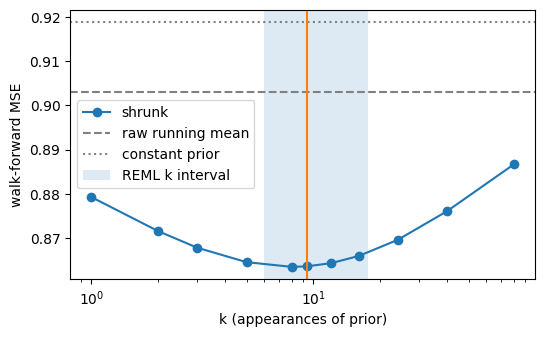

The sweep's best k is **8.0** (MSE 0.8634); every k from 8.0 to 12.0 is within 0.001 of it. The REML k of 9.4 gives 0.8635, so the two estimators agree. Shrinkage at all matters more than the exact k: raw running mean 0.9031, constant prior 0.9189.

In [6]:
KS = [1, 2, 3, 5, 8, 12, 16, 24, 40, 80]
ks = sorted(set(KS + [round(fit.k, 2)]))
sweep = rr.sweep_walk_forward(frame, fit.mu, fit.within_var, ks=ks)
display(sweep[["k", "mse_shrunk", "mse_raw_mean", "mse_prior", "mean_log_density"]])

best = sweep.loc[sweep["mse_shrunk"].idxmin()]
flat = sweep.loc[sweep["mse_shrunk"] <= best["mse_shrunk"] + 0.001, "k"]
at_fit = sweep.loc[(sweep["k"] - round(fit.k, 2)).abs().idxmin()]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogx(sweep["k"], sweep["mse_shrunk"], marker="o", label="shrunk")
ax.axhline(sweep["mse_raw_mean"].iloc[0], linestyle="--", color="grey", label="raw running mean")
ax.axhline(sweep["mse_prior"].iloc[0], linestyle=":", color="grey", label="constant prior")
ax.axvspan(table.loc["k", "ci_low"], min(table.loc["k", "ci_high"], 80), alpha=0.15, label="REML k interval")
ax.axvline(fit.k, color="C1")
ax.set_xlabel("k (appearances of prior)")
ax.set_ylabel("walk-forward MSE")
ax.legend()
plt.show()

say(
    f"The sweep's best k is **{best['k']:.1f}** (MSE {best['mse_shrunk']:.4f}); every k from "
    f"{flat.min():.1f} to {flat.max():.1f} is within 0.001 of it. The REML k of {fit.k:.1f} gives "
    f"{at_fit['mse_shrunk']:.4f}, so the two estimators "
    f"{'agree' if flat.min() <= fit.k <= flat.max() else 'disagree'}. Shrinkage at all matters more "
    f"than the exact k: raw running mean {best['mse_raw_mean']:.4f}, constant prior {best['mse_prior']:.4f}."
)

## Season drift

Drift is scored held out: for each career the filter uses constants fitted on the others, with `q` taken from a grid. Careers where nobody spans two seasons cannot respond to `q` (their scores are identical for every value), so only careers with enough multi-season players count toward the rule.

In [7]:
Q_GRID = [0.0, 0.002, 0.005, 0.01, 0.02, 0.05]
drift_parts = []
for q in Q_GRID:
    for c in careers:
        p = predict_held_out(c, drift=q)
        drift_parts.append(p.assign(drift=q, logd=log_density(p)))
drift = pd.concat(drift_parts, ignore_index=True)

by_q = drift.pivot_table(index="drift", columns="career", values="logd", aggfunc="mean")
by_q["pooled"] = drift.groupby("drift")["logd"].mean()
display(by_q)

q_star, gain_q, beats_each = 0.0, None, None
if identifiable:
    q_star = float(by_q[identifiable].mean(axis=1).idxmax())
    beats_each = all(by_q.loc[q_star, c] > by_q.loc[0.0, c] for c in identifiable)
    sub = drift[drift["career"].isin(identifiable)]
    best_q = sub[sub["drift"] == q_star].reset_index(drop=True)
    zero_q = sub[sub["drift"] == 0.0].reset_index(drop=True)
    gain_q = paired_gain(best_q["logd"] - zero_q["logd"], best_q["player_key"])
adopt_drift = (
    len(identifiable) >= 2 and q_star > 0 and bool(beats_each) and gain_q is not None and gain_q[1] > 0
)

if not identifiable:
    drift_text = "No career has enough multi-season players to identify drift."
else:
    drift_text = (
        f"Among {', '.join(identifiable)}, the best grid value is q = {q_star}; its log-density gain over "
        f"q = 0 is {gain_q[0]:.5f} per prediction ({span(gain_q[1], gain_q[2], 5)})."
    )
say(
    f"{drift_text} The rule needs at least two qualifying careers (there are {len(identifiable)}). "
    f"**Drift rule {'met: use q = ' + str(q_star) + '.' if adopt_drift else 'not met: keep q = 0.'}**"
)

career,arsenal_2,ipswich_3,valencia_cf_1,pooled
drift,,,,
0.000,-1.398,-1.275,-1.348,-1.350
0.002,-1.398,-1.275,-1.347,-1.349
0.005,-1.398,-1.275,-1.347,-1.349
0.010,-1.398,-1.275,-1.347,-1.349
0.020,-1.398,-1.275,-1.346,-1.349
0.050,-1.398,-1.275,-1.347,-1.349


Among valencia_cf_1, the best grid value is q = 0.02; its log-density gain over q = 0 is 0.00110 per prediction (-0.00169 to 0.00494). The rule needs at least two qualifying careers (there are 1). **Drift rule not met: keep q = 0.**

## Does the noise differ by position?

Descriptive only. The service uses one within-player variance for everyone; if it differs a lot by position, a single `k` is a compromise (it would be too weak for noisy positions and too strong for stable ones).

In [8]:
POSITION_GROUP = {
    "GK": "GK", "ST": "ST", "CF": "ST", "LW": "Winger", "RW": "Winger", "LM": "WM", "RM": "WM",
    "CAM": "CAM", "CM": "CM", "CDM": "CDM", "CB": "CB", "LB": "Fullback", "RB": "Fullback",
    "LWB": "Fullback", "RWB": "Fullback",
}
g = frame.assign(group=frame["primary_position"].map(POSITION_GROUP).fillna("Other"))
deviation = g["rating"] - g.groupby(["group", "player_key"])["rating"].transform("mean")
ss = (deviation**2).groupby(g["group"]).sum()
rows_by_group = g.groupby("group").size()
cells = g.groupby(["group", "player_key"]).size().groupby("group").size()
by_position = pd.DataFrame(
    {
        "rows": rows_by_group,
        "players": g.groupby("group")["player_key"].nunique(),
        "within_var": ss / (rows_by_group - cells),
        "mean_rating": g.groupby("group")["rating"].mean(),
    }
).sort_values("within_var")
display(by_position)

enough = by_position[by_position["rows"] >= 100]
ratio = enough["within_var"].max() / enough["within_var"].min()
say(
    f"Within-player variance runs from {enough['within_var'].min():.3f} ({enough['within_var'].idxmin()}) "
    f"to {enough['within_var'].max():.3f} ({enough['within_var'].idxmax()}) across groups with at least "
    f"100 rows, a ratio of {ratio:.2f}. "
    f"{'That is large enough to consider position-specific k later.' if ratio > 1.5 else 'A single k is reasonable.'}"
)

,rows,players,within_var,mean_rating
group,,,,
WM,72,9,0.237,6.228
CAM,29,5,0.594,6.479
Fullback,568,19,0.623,6.409
CDM,330,20,0.689,6.549
CM,570,28,0.739,6.418
CB,579,20,0.749,6.539
Winger,561,25,0.886,6.378
ST,333,17,1.030,6.538
GK,217,7,1.803,6.552


Within-player variance runs from 0.623 (Fullback) to 1.803 (GK) across groups with at least 100 rows, a ratio of 2.89. That is large enough to consider position-specific k later.

## Recommended constants

In [9]:
recommended_mu = fit.mu if adopt_fitted_mu else 6.0
recommended_q = q_star if adopt_drift else 0.0
final = pd.DataFrame(
    {
        "shipped": {
            "PRIOR_MEAN": ReliableRatingService.PRIOR_MEAN,
            "PRIOR_VARIANCE": ReliableRatingService.PRIOR_VARIANCE,
            "OBSERVATION_VARIANCE": ReliableRatingService.OBSERVATION_VARIANCE,
            "SEASON_DRIFT_VARIANCE": ReliableRatingService.SEASON_DRIFT_VARIANCE,
        },
        "recommended": {
            "PRIOR_MEAN": recommended_mu,
            "PRIOR_VARIANCE": fit.between_var,
            "OBSERVATION_VARIANCE": fit.within_var,
            "SEASON_DRIFT_VARIANCE": recommended_q,
        },
        "interval_low": {
            "PRIOR_MEAN": table.loc["mu", "ci_low"],
            "PRIOR_VARIANCE": table.loc["between_var", "ci_low"],
            "OBSERVATION_VARIANCE": table.loc["within_var", "ci_low"],
        },
        "interval_high": {
            "PRIOR_MEAN": table.loc["mu", "ci_high"],
            "PRIOR_VARIANCE": table.loc["between_var", "ci_high"],
            "OBSERVATION_VARIANCE": table.loc["within_var", "ci_high"],
        },
    }
)
display(final)

data_text = ", ".join(f"{c} ({n})" for c, n in info["available"].items())
say(
    "Paste into `ReliableRatingService`, replacing the provisional comments:\n\n```python\n"
    f"# Fitted on config {info['hash'][:8]}: {len(frame):,} rated appearances by {fit.n_players} players\n"
    f"# (matches per career: {data_text}); REML, row-pooled; 95% intervals from a player bootstrap.\n"
    f"PRIOR_MEAN: Final[float] = {recommended_mu:.3f}\n"
    f"PRIOR_VARIANCE: Final[float] = {fit.between_var:.3f}\n"
    f"OBSERVATION_VARIANCE: Final[float] = {fit.within_var:.3f}\n"
    f"SEASON_DRIFT_VARIANCE: Final[float] = {recommended_q}\n```"
)

,shipped,recommended,interval_low,interval_high
PRIOR_MEAN,6.442,6.442,6.368,6.515
PRIOR_VARIANCE,0.088,0.088,0.048,0.136
OBSERVATION_VARIANCE,0.826,0.826,0.716,0.948
SEASON_DRIFT_VARIANCE,0.000,0.000,NaN,NaN


Paste into `ReliableRatingService`, replacing the provisional comments:

```python
# Fitted on config 005d563f: 3,259 rated appearances by 96 players
# (matches per career: arsenal_2 (38), ipswich_3 (22), valencia_cf_1 (157)); REML, row-pooled; 95% intervals from a player bootstrap.
PRIOR_MEAN: Final[float] = 6.442
PRIOR_VARIANCE: Final[float] = 0.088
OBSERVATION_VARIANCE: Final[float] = 0.826
SEASON_DRIFT_VARIANCE: Final[float] = 0.0
```